# Setup & Load Untouched Raw Data (Kaggle CSV)

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    classification_report, precision_recall_curve
)
from lightgbm import LGBMClassifier
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Anchor working directory to day-14-online-shopper-intention/src
PROJECT_SRC = r"C:\Users\adjis\github\100-days-real-world-ml\day-14-online-shopper-intention\src"
if os.path.exists(PROJECT_SRC):
    os.chdir(PROJECT_SRC)
os.makedirs("outputs", exist_ok=True)

CSV_PATH = "../data/raw/online_shoppers_intention.csv"
df_raw = pd.read_csv(CSV_PATH)
print(f"Working directory : {os.getcwd()}")
print(f"Raw Dataset Shape : {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Working directory : C:\Users\adjis\github\100-days-real-world-ml\day-14-online-shopper-intention\src
Raw Dataset Shape : 12,330 rows, 18 columns


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


# EDA 1: Schema, Duplicates, Zero-Inflated PageValues & Collinearity Audit

In [2]:
print(f"Standard Nulls       : {df_raw.isnull().sum().sum()}")
print(f"Exact Duplicate Rows : {df_raw.duplicated().sum()} ({df_raw.duplicated().mean():.2%})")

audit_records = []
for col in df_raw.columns:
    audit_records.append({
        "Column": col,
        "Dtype": str(df_raw[col].dtype),
        "Unique_Values": df_raw[col].nunique(),
        "Zero_Pct (%)": round((df_raw[col] == 0).mean() * 100, 2) if df_raw[col].dtype in ["int64", "float64"] else "-",
        "Sample_Values": str(df_raw[col].unique()[:3]),
    })
display(pd.DataFrame(audit_records))

# Verify multicollinearity between BounceRates & ExitRates and zero-inflation of PageValues
bounce_exit_corr = df_raw["BounceRates"].corr(df_raw["ExitRates"])
pv_zero_conv = df_raw.loc[df_raw["PageValues"] == 0, "Revenue"].mean() * 100
pv_pos_conv = df_raw.loc[df_raw["PageValues"] > 0, "Revenue"].mean() * 100

print(f"\n[COLLINEARITY CHECK] Pearson r(BounceRates, ExitRates) = {bounce_exit_corr:.4f}")
print(f"[ZERO-INFLATION INSIGHT] Conversion when PageValues == 0: {pv_zero_conv:.2f}% vs. PageValues > 0: {pv_pos_conv:.2f}%")

Standard Nulls       : 0
Exact Duplicate Rows : 125 (1.01%)


,Column,Dtype,Unique_Values,Zero_Pct (%),Sample_Values
0,Administrative,int64,27,46.78,[0 1 2]
1,Administrative_Duration,float64,3335,47.88,[ 0. 53. 64.6]
2,Informational,int64,17,78.66,[0 1 2]
3,Informational_Duration,float64,1258,80.49,[ 0. 120. 16.]
4,ProductRelated,int64,311,0.31,[ 1 2 10]
5,ProductRelated_Duration,float64,9551,6.12,[ 0. 64. 2.66666667]
6,BounceRates,float64,1872,44.75,[0.2 0. 0.05]
7,ExitRates,float64,4777,0.62,[0.2 0.1 0.14]
8,PageValues,float64,2704,77.86,[ 0. 54.17976426 19.44707913]
9,SpecialDay,float64,6,89.85,[0. 0.4 0.8]



[COLLINEARITY CHECK] Pearson r(BounceRates, ExitRates) = 0.9130
[ZERO-INFLATION INSIGHT] Conversion when PageValues == 0: 3.85% vs. PageValues > 0: 56.34%


# EDA 2: Target Imbalance, Visitor/Seasonal Conversion & Visual Dashboard

Target Variable ('Revenue') Distribution:


,Count,Percentage (%)
Revenue,,
False,10422,84.53
True,1908,15.47


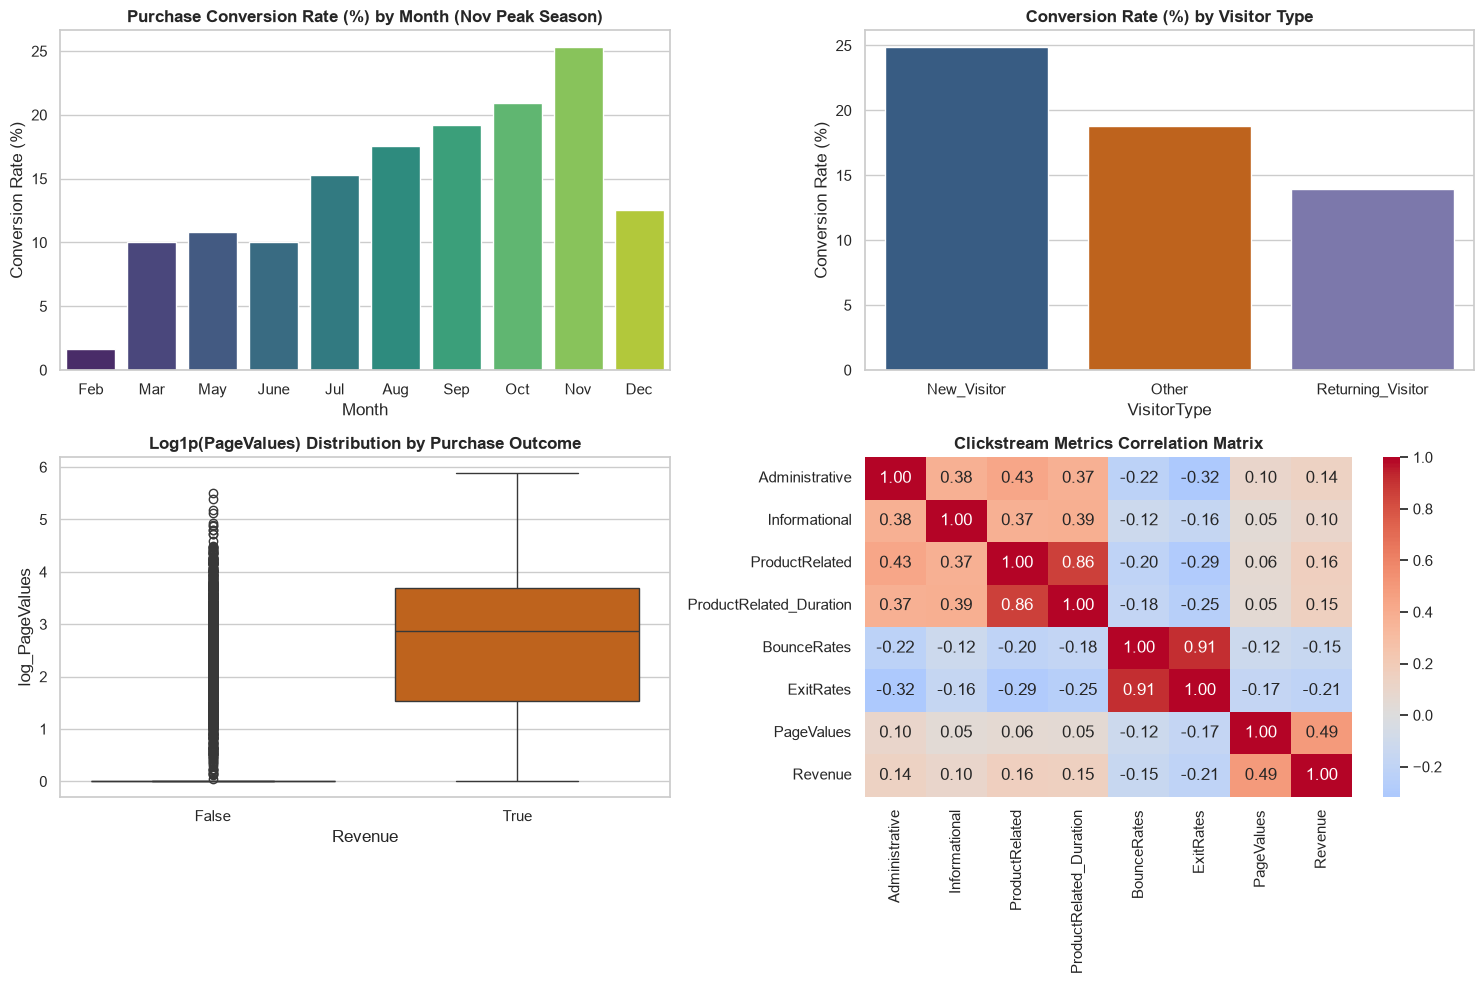

In [3]:
print("Target Variable ('Revenue') Distribution:")
display(pd.DataFrame({
    "Count": df_raw["Revenue"].value_counts(),
    "Percentage (%)": (df_raw["Revenue"].value_counts(normalize=True) * 100).round(2)
}))

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Conversion Rate by Month (Ordered chronologically across the 10 available months)
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
avail_months = [m for m in month_order if m in df_raw["Month"].unique()]
month_conv = df_raw.groupby("Month")["Revenue"].mean().loc[avail_months] * 100
sns.barplot(x=month_conv.index, y=month_conv.values, palette="viridis", ax=axes[0, 0])
axes[0, 0].set_title("Purchase Conversion Rate (%) by Month (Nov Peak Season)", fontweight="bold")
axes[0, 0].set_ylabel("Conversion Rate (%)")

# Plot 2: Conversion Rate by VisitorType
vis_conv = df_raw.groupby("VisitorType")["Revenue"].mean().sort_values(ascending=False) * 100
sns.barplot(x=vis_conv.index, y=vis_conv.values, palette=["#2b5c8f", "#d95f02", "#7570b3"], ax=axes[0, 1])
axes[0, 1].set_title("Conversion Rate (%) by Visitor Type", fontweight="bold")
axes[0, 1].set_ylabel("Conversion Rate (%)")

# Plot 3: Log(PageValues + 1) vs Revenue Boxplot
df_raw_plot = df_raw.copy()
df_raw_plot["log_PageValues"] = np.log1p(df_raw_plot["PageValues"])
sns.boxplot(data=df_raw_plot, x="Revenue", y="log_PageValues", palette=["#2b5c8f", "#d95f02"], ax=axes[1, 0])
axes[1, 0].set_title("Log1p(PageValues) Distribution by Purchase Outcome", fontweight="bold")

# Plot 4: Numerical Feature Correlation Heatmap
num_cols_corr = [
    "Administrative", "Informational", "ProductRelated",
    "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "Revenue"
]
corr_mat = df_raw[num_cols_corr].astype(float).corr()
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1, 1])
axes[1, 1].set_title("Clickstream Metrics Correlation Matrix", fontweight="bold")

plt.tight_layout()
plt.savefig("outputs/eda_online_shoppers.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning

In [4]:
"""
Cleaning Rules Driven by EDA Findings:
1. Drop 125 exact duplicate rows discovered in Cell 2 (leaves 12,205 unique sessions).
2. Cast boolean columns ('Weekend', 'Revenue') to integer 0/1 flags.
3. Cast false-numeric Google Analytics IDs ('OperatingSystems', 'Browser', 'Region', 'TrafficType')
   to categorical strings, and consolidate ultra-rare categories (< 1% frequency) into 'Other'
   after train-test split to avoid sparse overfitting.
4. Standardize 'June' -> 'Jun' for consistent 3-letter month naming.
"""
df_clean = df_raw.drop_duplicates().reset_index(drop=True)
df_clean["Weekend"] = df_clean["Weekend"].astype(int)
df_clean["Revenue"] = df_clean["Revenue"].astype(int)
df_clean["Month"] = df_clean["Month"].replace({"June": "Jun"})

for ga_id in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
    df_clean[ga_id] = df_clean[ga_id].astype(str)

print(f"Raw Rows: {len(df_raw):,} -> Cleaned Unique Sessions: {len(df_clean):,} | Conversion Rate: {df_clean['Revenue'].mean():.2%}")

Raw Rows: 12,330 -> Cleaned Unique Sessions: 12,205 | Conversion Rate: 15.63%


# Clickstream Engagement Feature Engineering & Leak-Free Preprocessing

In [5]:
df_feat = df_clean.copy()

# 1. Total session depth, total time spent & average time per product page
df_feat["total_pages"] = df_feat["Administrative"] + df_feat["Informational"] + df_feat["ProductRelated"]
df_feat["total_duration"] = (
    df_feat["Administrative_Duration"] + df_feat["Informational_Duration"] + df_feat["ProductRelated_Duration"]
)
df_feat["avg_time_per_product_page"] = df_feat["ProductRelated_Duration"] / (df_feat["ProductRelated"] + 1.0)
df_feat["product_page_share"] = df_feat["ProductRelated"] / (df_feat["total_pages"] + 1.0)

# 2. Zero-inflated PageValues indicator & log-compressed engagement metrics
df_feat["has_nonzero_page_value"] = (df_feat["PageValues"] > 0).astype(int)
df_feat["log_page_values"] = np.log1p(df_feat["PageValues"])
df_feat["log_total_duration"] = np.log1p(df_feat["total_duration"])

# 3. Combined bounce-exit friction ratio (mitigates r = 0.91 collinearity)
df_feat["exit_minus_bounce"] = np.maximum(df_feat["ExitRates"] - df_feat["BounceRates"], 0.0)

X = df_feat.drop(columns=["Revenue"])
y = df_feat["Revenue"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Group rare GA IDs (< 1% prevalence in X_train) strictly inside training fold
for ga_id in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
    freq = X_train[ga_id].value_counts(normalize=True)
    common_vals = freq[freq >= 0.01].index.tolist()
    X_train[ga_id] = X_train[ga_id].where(X_train[ga_id].isin(common_vals), "Other")
    X_test[ga_id] = X_test[ga_id].where(X_test[ga_id].isin(common_vals), "Other")

cat_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
])

print(f"Train Set: {X_train.shape} (Purchases: {y_train.sum():,}) | Test Set: {X_test.shape} (Purchases: {y_test.sum():,})")

Train Set: (9764, 25) (Purchases: 1,526) | Test Set: (2441, 25) (Purchases: 382)


# Model Benchmarking (Logistic Regression vs. LightGBM Clickstream Engine)

In [6]:
def find_optimal_f1_threshold(y_true, y_probs):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
    best_idx = np.argmax(f1_scores[:-1])
    return float(thresholds[best_idx])

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression (Balanced Baseline)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
    ]),
    "LightGBM (Clickstream Conversion Engine)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LGBMClassifier(
            n_estimators=300,
            learning_rate=0.04,
            num_leaves=31,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=np.sqrt(scale_pos_weight),
            n_jobs=-1,
            random_state=42,
            verbose=-1,
        )),
    ]),
}

best_model, best_pr_auc = None, 0.0

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_probs = pipeline.predict_proba(X_test)[:, 1]
    opt_thresh = find_optimal_f1_threshold(y_test, y_probs)
    y_pred = (y_probs >= opt_thresh).astype(int)

    roc_auc = roc_auc_score(y_test, y_probs)
    pr_auc = average_precision_score(y_test, y_probs)

    print(f"\n---> {name}")
    print(f"PR-AUC : {pr_auc:.4f} | ROC-AUC : {roc_auc:.4f} | Optimal F1 Threshold : {opt_thresh:.4f}")
    print(classification_report(y_test, y_pred, target_names=["No Purchase (0)", "Purchased (1)"]))

    if pr_auc > best_pr_auc:
        best_pr_auc = pr_auc
        best_model = pipeline

joblib.dump(best_model, "outputs/best_shopper_intention_model.joblib")


---> Logistic Regression (Balanced Baseline)
PR-AUC : 0.6892 | ROC-AUC : 0.9270 | Optimal F1 Threshold : 0.6320
                 precision    recall  f1-score   support

No Purchase (0)       0.96      0.90      0.93      2059
  Purchased (1)       0.60      0.79      0.68       382

       accuracy                           0.88      2441
      macro avg       0.78      0.85      0.81      2441
   weighted avg       0.90      0.88      0.89      2441


---> LightGBM (Clickstream Conversion Engine)
PR-AUC : 0.7407 | ROC-AUC : 0.9308 | Optimal F1 Threshold : 0.4977
                 precision    recall  f1-score   support

No Purchase (0)       0.95      0.93      0.94      2059
  Purchased (1)       0.66      0.74      0.70       382

       accuracy                           0.90      2441
      macro avg       0.80      0.83      0.82      2441
   weighted avg       0.90      0.90      0.90      2441



['outputs/best_shopper_intention_model.joblib']

# Fast SHAP Explainability (Subsampled for Instant Local Execution)

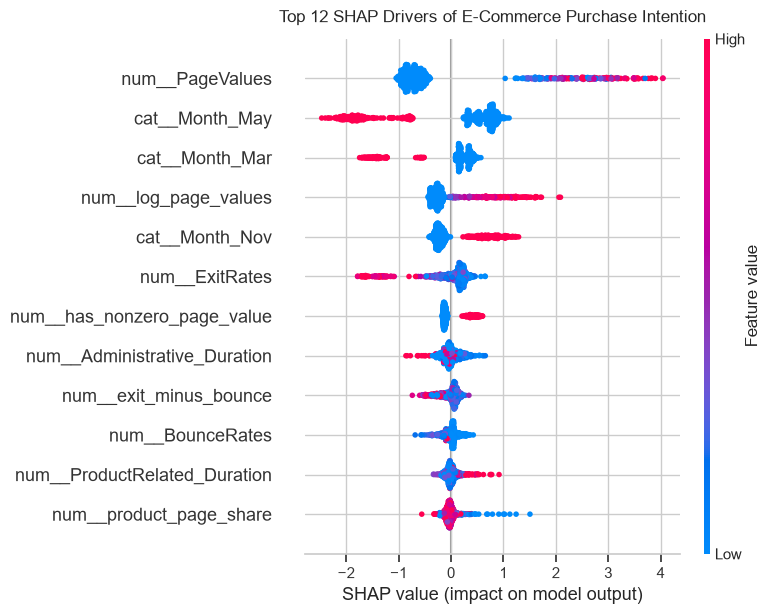

In [7]:
lgbm_pipe = models["LightGBM (Clickstream Conversion Engine)"]

X_test_sample = X_test.sample(min(800, len(X_test)), random_state=42)
X_test_transformed = lgbm_pipe.named_steps["preprocessor"].transform(X_test_sample)
feature_names = lgbm_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(lgbm_pipe.named_steps["classifier"])
shap_values = explainer.shap_values(X_test_transformed)
shap_vals_to_plot = shap_values[1] if isinstance(shap_values, list) else shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_to_plot, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Drivers of E-Commerce Purchase Intention", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_online_shoppers.png", dpi=150)
plt.show()

In [8]:
# Cell 8 — Ablation Study: Conversion Prediction WITHOUT PageValues (Pure Browsing Behavior)
pv_cols = ["PageValues", "has_nonzero_page_value", "log_page_values"]

X_tr_nopv = X_train.drop(columns=pv_cols)
X_te_nopv = X_test.drop(columns=pv_cols)

cat_nopv = X_tr_nopv.select_dtypes(include=["object"]).columns.tolist()
num_nopv = [c for c in X_tr_nopv.columns if c not in cat_nopv]

prep_nopv = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_nopv),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_nopv),
])

lgbm_nopv = Pipeline([
    ("preprocessor", prep_nopv),
    ("classifier", LGBMClassifier(
        n_estimators=300, learning_rate=0.04, num_leaves=31, max_depth=6,
        subsample=0.8, colsample_bytree=0.8, scale_pos_weight=np.sqrt(scale_pos_weight),
        n_jobs=-1, random_state=42, verbose=-1
    )),
])
lgbm_nopv.fit(X_tr_nopv, y_train)

probs_full = models["LightGBM (Clickstream Conversion Engine)"].predict_proba(X_test)[:, 1]
probs_nopv = lgbm_nopv.predict_proba(X_te_nopv)[:, 1]

comp_day14 = pd.DataFrame([
    {
        "Feature_Set": "Full Clickstream (WITH PageValues)",
        "PR-AUC": average_precision_score(y_test, probs_full),
        "ROC-AUC": roc_auc_score(y_test, probs_full),
    },
    {
        "Feature_Set": "Browsing-Only (WITHOUT PageValues)",
        "PR-AUC": average_precision_score(y_test, probs_nopv),
        "ROC-AUC": roc_auc_score(y_test, probs_nopv),
    },
])
display(comp_day14.round(4))

,Feature_Set,PR-AUC,ROC-AUC
0,Full Clickstream (WITH PageValues),0.7407,0.9308
1,Browsing-Only (WITHOUT PageValues),0.3659,0.7862
